In [ ]:
# %matplotlib notebook

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

In [2]:
import sys
print(sys.executable)

/Users/wynne/github/cp2-worm-algorithm-cpp/analysis/venv/bin/python3


In [394]:
def average_over_corr_measurements(corr, X, T, n_drop):
    """
    There are 20 correlator measurments outputed by each C++ run. This function averages over these 20 measurements.
    
    :param data: The correlator data. The X index runs faster than the T index.
    :param X: The x-direction lattice size.
    :param T: The t-direction lattice size divided by 4. We want real time not trotter time.
    
    :type data: pandas dataframe
    :type X: int
    :type T: int
    
    """
    
    len_repeat = X*T
    
    corr = corr[n_drop*len_repeat:]
    
    avg_corrs_modulo = [ list(corr.iloc[i::len_repeat, :].mean(axis=0)) for i in range(len_repeat) ]
    result = pd.DataFrame(avg_corrs_modulo, columns=corr.columns)
    
    return result

In [411]:
def plot_corr_3d(corr_path, operator, X, T):
    
    names = ['a','b','c','d','e','f','g','h','i','j','k','l']
    
    corr = pd.read_csv(corr_path, names=names)
    
    avg_corr = average_over_corr_measurements(corr, X, T, 2)
    
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    x = [i for j in range(T) for i in range(X)]
    y = [j for j in range(T) for i in range(X)]
    z = list(avg_corr[operator])
    

    ax.scatter(x, y, z, c='r', marker='o')

    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')

    plt.show()
    
    

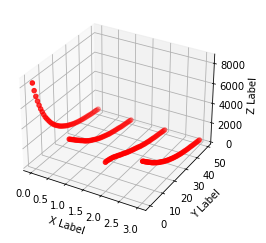

In [414]:
plot_corr_3d("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_2.50_XYT_4_4_200_mu3_0.000_mu8_0.000_nSim_1.dat",
             'a', 4, 50)

In [421]:
def average_correlators_X(corr, X):
    """
    corr: pandas dataframe
    correlators outputed by C++ worm algorithm
    
    X: int 
    x-dimension size
    
    """
    
    #C0 = corr.iloc[0::X, :].mean(axis=0)
    C0 = corr.iloc[0]
    avg_corrs_modulo = [ list(corr.iloc[i::X, :].mean(axis=0)/C0) for i in range(X) ]
    result = pd.DataFrame(avg_corrs_modulo, columns=corr.columns)
    
    
    return result

In [422]:
def average_correlators_T(corr, X, T):
    """
    corr: pandas dataframe
    correlators outputed by C++ worm algorithm
    
    T: int 
    t-dimension size
    """
    
    names=['a','b','c','d','e','f','g','h','i','j','k','l']
    d = pd.DataFrame(0.0, index=np.arange(T), columns=names)
    for i in range(X):
        d = d + corr.iloc[i::X, :].reset_index(drop=True)
    d_norm = d/d.iloc[0]
    
    return d_norm

In [11]:
from scipy.optimize import curve_fit

In [39]:
def make_cosh_func(L):
    def cosh_func(x, z, l):
        return z * np.cosh(((L/2)-x)/l)
    return cosh_func

In [153]:
def make_exp_func(L):
    def exp_func(x, z, l):
        return z * np.exp(-x/l)
    return exp_func

In [164]:
def make_altexp_func(L):
    def altexp_func(x, z, l):
        return z * ((L - x)*np.exp(-x/l) + x*np.exp(-(L - x)/l))
    return altexp_func

In [154]:
def fit_func(func, xdata, ydata, p0, bounds):
    if bounds:
        popt, pcov = curve_fit(func, xdata, ydata, p0=p0, bounds=bounds)
    else:
        popt, pcov = curve_fit(func, xdata, ydata, p0=p0)
    return popt, pcov

In [155]:
def fit_plot(make_func, ydata, L, L_start, L_end, p0, bounds):
    
    xdata = np.arange(L)
    popt, pcov = fit_func(make_func(L), xdata[L_start:L_end], ydata[L_start:L_end], p0, bounds)
    
    fig, ax = plt.subplots()
    plt.plot(xdata[L_start:L_end], ydata[L_start:L_end], 'b-', label='data')
    plt.plot(xdata[L_start:L_end], make_func(L)(xdata[L_start:L_end], *popt), 'g--', label='fit: z=%5.3f, l=%5.3f' % tuple(popt))
    plt.legend()
    plt.show()

In [423]:
def average_and_plot(corr_path, X, T):
    names = ['a','b','c','d','e','f','g','h','i','j','k','l']
    corr = pd.read_csv(corr_path, names=names)
    avg_corr = average_over_corr_measurements(corr, X, T, 2)
    avg_corr_X = average_correlators_X(avg_corr, X)
    avg_corr_T = average_correlators_T(avg_corr, X, T)
    print(type(avg_corr))
    fig, axs = plt.subplots(len(avg_corr.columns),2, figsize=(10,20))
    for i, (col, ax) in enumerate(zip(avg_corr.columns, axs)):
        sns.lineplot(data=avg_corr_X[col], ax=ax[0])
        sns.lineplot(data=avg_corr_T[col], ax=ax[1])
    plt.subplots_adjust(hspace=0.5)
    plt.show()

<class 'pandas.core.frame.DataFrame'>


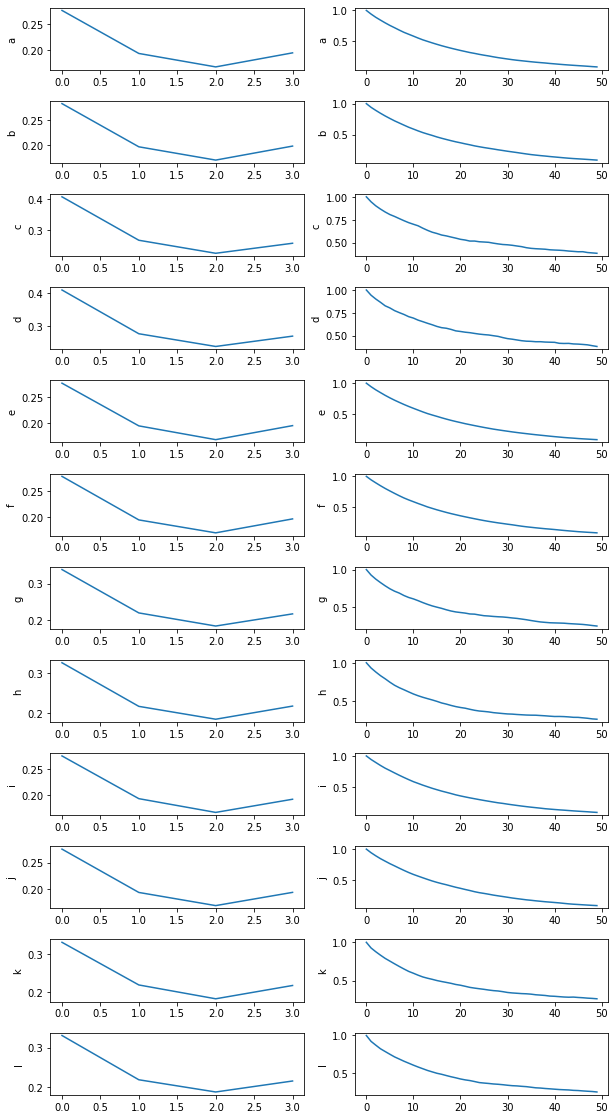

In [425]:
average_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_2.50_XYT_4_4_200_mu3_0.000_mu8_0.000_nSim_1.dat", 
             4, 50)

In [434]:
def fit_and_plot(corr_path, X, T, X_start=None, X_end=None, Y_start=None, Y_end=None, p0X=None, p0T=None, boundsX=None, boundsT=None):
    names = ['a','b','c','d','e','f','g','h','i','j','k','l']
    
    corr = pd.read_csv(corr_path, names=names)
    avg_corr = average_over_corr_measurements(corr, X, T, 2)
    avg_corr_X = average_correlators_X(avg_corr, X)
    avg_corr_T = average_correlators_T2(avg_corr, X, T)
    
    #fig, axs = plt.subplots(1,2)
    #sns.lineplot(data=avg_corr_X['a'], ax=axs[0])
    #sns.lineplot(data=avg_corr_T['a'], ax=axs[1])
    #for ax in axs:
    #    ax.legend(loc='right')
    #plt.show()
    
    ydataT = avg_corr_T['a'].to_numpy()
    
    fit_plot(make_cosh_func, avg_corr_X['a'].to_numpy(), X, X_start, X_end, p0X, boundsX)
    fit_plot(make_exp_func, avg_corr_T['a'].to_numpy(), T, Y_start, Y_end, p0T, boundsT)
    #fit_plot(make_altexp_func, avg_corr_T['a'].to_numpy(), T, Y_start, Y_end, p0T, boundsT)

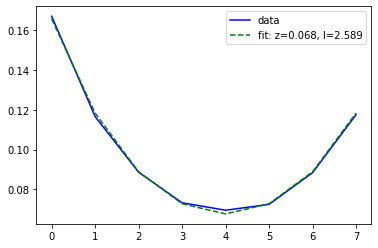

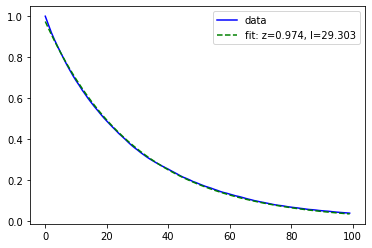

In [440]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_5.00_XYT_8_4_400_mu3_0.000_mu8_0.000_nSim_1.dat", 
             8, 100, boundsX=([0, 0],[10000, 10000]), boundsT=([0, 0],[20000, 10000]))

<ipython-input-39-bddbe5a695da>:3: RuntimeWarning: overflow encountered in cosh
  return z * np.cosh(((L/2)-x)/l)


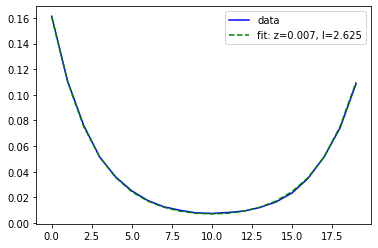

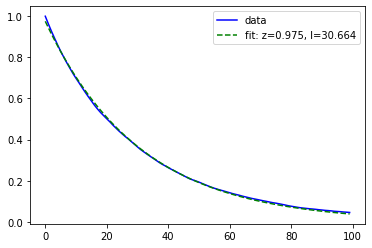

In [437]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_5.00_XYT_20_4_400_mu3_0.000_mu8_0.000_nSim_1.dat", 
             20, 100, boundsX=([0, 0],[10000, 10000]), boundsT=([0, 0],[10000, 10000]))

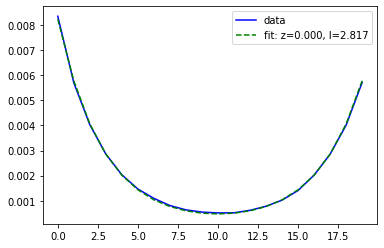

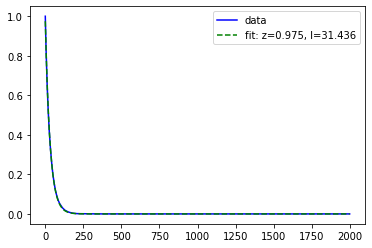

In [447]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_100.00_XYT_20_4_8000_mu3_0.000_mu8_0.000_nSim_1.dat", 
             20, 2000)

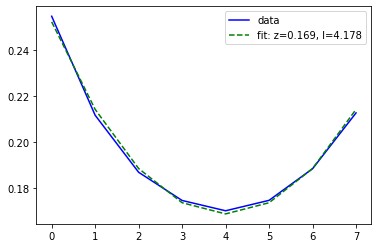

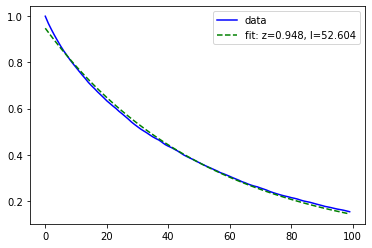

In [438]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_5.00_XYT_8_8_400_mu3_0.000_mu8_0.000_nSim_1.dat", 
             8, 100, boundsX=([0, 0],[10000, 10000]), boundsT=([0, 0],[10000, 10000]))

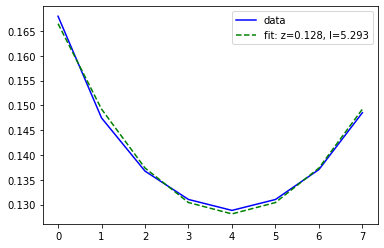

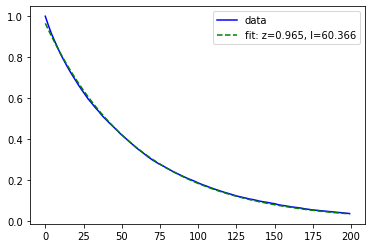

In [441]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_10.00_XYT_8_8_800_mu3_0.000_mu8_0.000_nSim_1.dat", 
             8, 200, boundsX=([0, 0],[10000, 10000]), boundsT=([0, 0],[20000, 20000]))

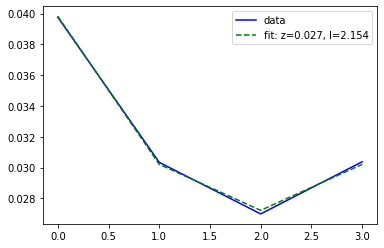

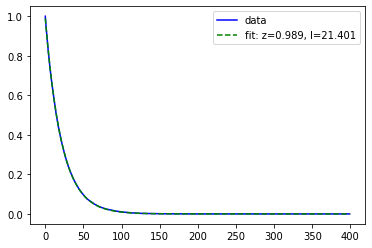

In [446]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_20.00_XYT_4_4_1600_mu3_0.000_mu8_0.000_nSim_1.dat", 
             4, 400, boundsX=([0, 0],[2, 200]), boundsT=([0, 0],[2, 200]))

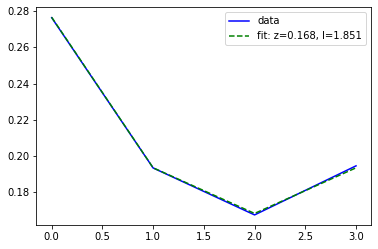

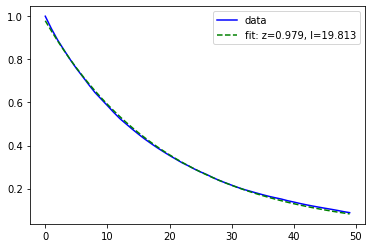

In [436]:
fit_and_plot("../data/" \
             "C_wormCP2AFMmu2dplaq_BC_closed_nMeas_100000_beta_2.50_XYT_4_4_200_mu3_0.000_mu8_0.000_nSim_1.dat", 
             4, 50, boundsX=([0, 0],[10000, 10000]), boundsT=([0, 0],[10000, 10000]))